Clase 011 · `011_matplotlib2` · Seis años de ESOLMET (agosto de 2020 a agosto de 2026) en
un solo Parquet. Exploración visual: varios paneles con `plt.subplots(2, 1)`, qué hace
`sharex`, cómo graficar varias columnas de una vez y cómo elegir columnas por nombre con un
ciclo. Termina guardando un mes en `data/002_intermediate/` para la libreta siguiente.

::: {.callout-important title="Datos"}
El archivo `ClimaLab_2020-08-05_2026-08-05.parquet` no viaja en el repositorio; colócalo en
`clases/011_matplotlib2/data/001_raw/` (se comparte en clase). Esta libreta escribe
`esolmet_1mes_3marzo.parquet` en `data/002_intermediate/`.
:::

## Librerías

`pandas`, `matplotlib` y `parse` para escribir fechas como texto. El proyecto de esta clase
se creó con `uv init` y las dependencias con `uv add pandas matplotlib pyarrow`.

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from dateutil.parser import parse

## Leer el Parquet

Parquet guarda los tipos y el índice de fechas, así que `read_parquet` no necesita
`index_col` ni `parse_dates`. El `info()` quedó comentado: en clase se usó para ver las
columnas y después se silenció para no imprimirlo cada vez.

In [7]:
f = "../data/001_raw/ClimaLab_2020-08-05_2026-08-05.parquet"
esolmet = pd.read_parquet(f)
# esolmet.info()

Otra inspección que quedó comentada; descoméntala para ver el `DatetimeIndex`.

In [8]:
# esolmet.index

## Dos paneles con `sharex=True`

`plt.subplots(2, 1)` crea dos `Axes` apilados y los devuelve en un arreglo: `ax[0]` es el
de arriba y `ax[1]` el de abajo. Con `sharex=True` los dos comparten el eje horizontal, por
eso basta `ax[0].set_xlim(f1, f2)` para que ambos muestren la misma semana de marzo de 2024.

Arriba la temperatura de bulbo seco (`tdb`, con la etiqueta `tbd` tal como se escribió en
clase) oscila entre 20 y 35 °C cada día; abajo `dhi` y `dni` dibujan campanas que se
recortan los días nublados. La tupla impresa antes de la figura es el valor que devuelve
`set_xlim`.

(np.float64(19792.0), np.float64(19799.0))

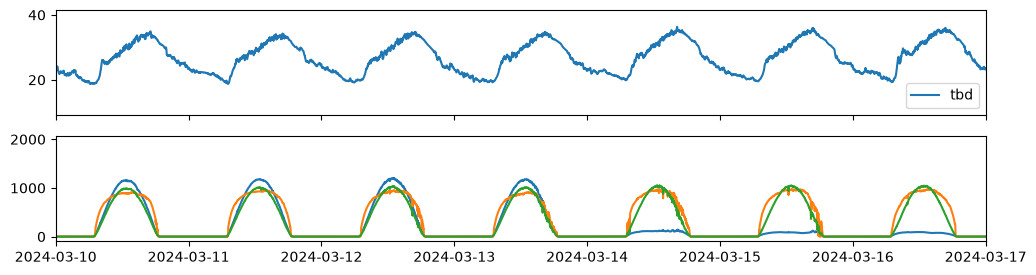

In [13]:
#| label: fig-eda-paneles-sharex
#| fig-cap: "Una semana de marzo de 2024 en dos paneles con `sharex=True`: temperatura de bulbo seco arriba e irradiancias difusa y directa abajo. Un solo `set_xlim` recorta los dos paneles."
#| fig-alt: "Dos paneles apilados; arriba una línea azul de temperatura que oscila entre 20 y 35 grados cada día, abajo campanas naranja y verde de irradiancia que llegan a 1000 W/m², con dos días irregulares al final."
fig, ax = plt.subplots(2,1,figsize=(12,3),sharex=True)
f1 = parse("2024-03-10")
f2 = f1 + pd.Timedelta("7D")

ax[0].plot(esolmet.tdb,label="tbd")
ax[1].plot(esolmet.dhi,label="dhi")
ax[1].plot(esolmet.dni,label="dni")
# ax[1].plot(esolmet.ghi,label="ghi")

ax[0].legend()
ax[0].set_xlim(f1,f2)

## Una malla de 2×3: `ax[fila, columna]`

Con dos filas y tres columnas `ax` es un arreglo bidimensional y cada panel se indexa como
`ax[1, 2]`. Sólo ese panel recibe datos; los otros cinco quedan vacíos pero comparten ejes
(`sharex` y `sharey`), por eso todos muestran de 2021 a 2026 y de 20 a 40 °C. La salida
`[<matplotlib.lines.Line2D ...>]` es lo que devuelve `plot`.

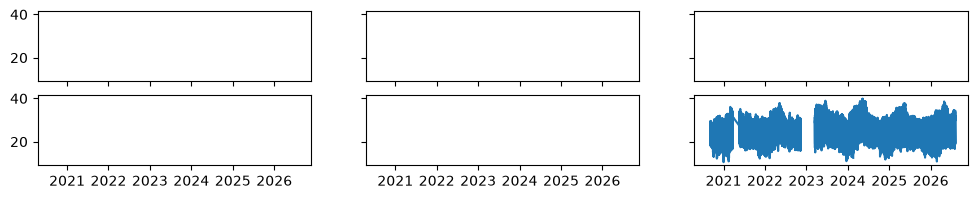

In [19]:
#| label: fig-eda-malla-2x3
#| fig-cap: "Malla de 2×3 `Axes` con un solo panel dibujado, `ax[1, 2]`. Los seis comparten ejes, por eso todos muestran el mismo rango aunque estén vacíos."
#| fig-alt: "Seis cuadros vacíos en dos filas y tres columnas; sólo el de abajo a la derecha tiene una serie azul densa de 2021 a 2026."
fig, ax = plt.subplots(2,3,figsize=(12,2),sharex=True,sharey=True)

ax[1,2].plot(esolmet.tdb)


## Desempacar los ejes: `(ax1, ax2)`

Alternativa al arreglo: desempacar los dos `Axes` en nombres propios. Sin `set_xlim` se ven
los seis años completos y aparecen los huecos de la estación: las líneas rectas de 2021 y
2022 unen el último dato antes de un apagón con el primero después, y a finales de 2022 la
estación no midió durante meses.

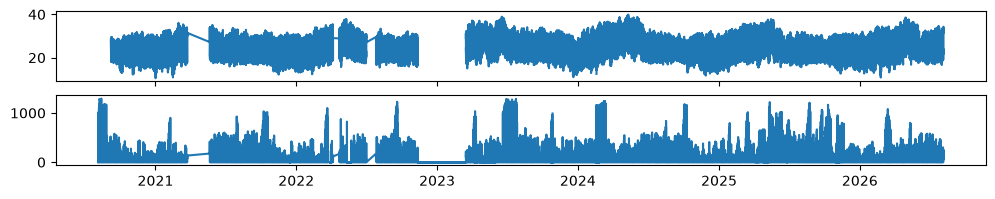

In [28]:
#| label: fig-eda-seis-anios
#| fig-cap: "Seis años de temperatura (arriba) e irradiancia difusa (abajo). Las líneas rectas de 2021 y 2022 y el vacío de finales de 2022 son periodos sin medición."
#| fig-alt: "Dos paneles con series azules densas de 2020 a 2026; en el panel superior hay dos tramos rectos y un hueco entre finales de 2022 y principios de 2023."
fig, (ax1,ax2) = plt.subplots(2,1,figsize=(12,2),sharex=True)

ax1.plot(esolmet.tdb)

ax2.plot(esolmet.dhi)

## Varias columnas en una llamada

Si `plot` recibe un `DataFrame` dibuja una línea por columna; `label` acepta entonces una
lista con un nombre por línea. `loc="upper center"` coloca la leyenda arriba al centro.

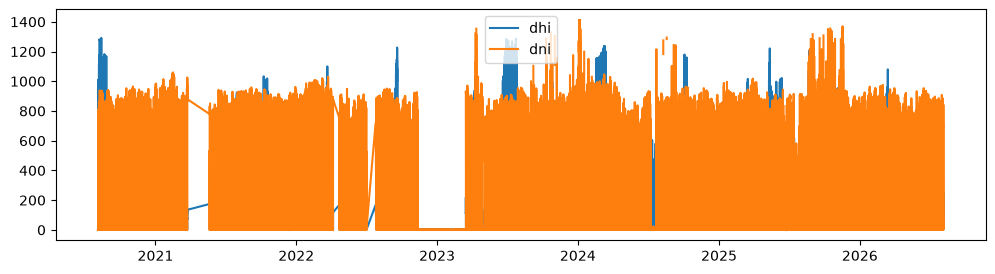

In [33]:
#| label: fig-eda-dhi-dni
#| fig-cap: "Irradiancia difusa y directa de los seis años dibujadas con una sola llamada a `plot` sobre un `DataFrame` de dos columnas."
#| fig-alt: "Serie naranja densa de irradiancia directa hasta 1400 W/m² que cubre casi toda la figura, con picos azules de difusa asomando; leyenda arriba al centro."
Is = ["dhi","dni"]

fig, ax = plt.subplots(figsize=(12,3))

ax.plot(esolmet[Is],label=Is)
ax.legend(loc="upper center")

Las diez columnas del `DataFrame`.

In [34]:
esolmet.columns

Index(['dhi', 'dni', 'ghi', 'p_atm', 'rain_acc', 'rh', 'tdb', 'uv', 'wd',
       'ws'],
      dtype='str', name='variable')

## Elegir columnas por nombre con un ciclo

Recorremos los nombres y nos quedamos con los que contienen una `h`. Entran `dhi` y `ghi`,
que era la intención, pero también `rh`, la humedad relativa: filtrar por un trozo del
nombre es frágil y hay que revisar lo que devuelve.

In [41]:
columnas = []
for columna in esolmet.columns:
    if "h" in columna:
        print(columna)
        columnas.append(columna)

columnas

dhi
ghi
rh


['dhi', 'ghi', 'rh']

## Energía acumulada: sumar minutos

Sumar irradiancia (W/m²) registrada cada minuto y multiplicar por 1/60 da energía en Wh/m².
El factor supone un dato por minuto; si la frecuencia fuera otra, cambia.

In [43]:
esolmet.dhi.sum()*1/60

np.float64(3790392.254333333)

## Lo mismo con una comprensión de lista

La suma de cada columna con `h` en una sola expresión: tres números, uno por columna.

In [44]:
[esolmet[columna].sum()*1/60 for columna in esolmet.columns if "h" in columna]

[np.float64(3790392.254333333),
 np.float64(10985542.360000001),
 np.float64(2476654.1621500007)]

## Una línea por columna con un ciclo

La comprensión de lista guarda las columnas y el ciclo las dibuja una por una sobre el
mismo `Axes`. La figura enseña un problema: `rh` está en porcentaje y queda aplastada como
una línea verde al fondo junto a las irradiancias en W/m². Variables con unidades distintas
no comparten eje; para eso están los paneles o `twinx`.

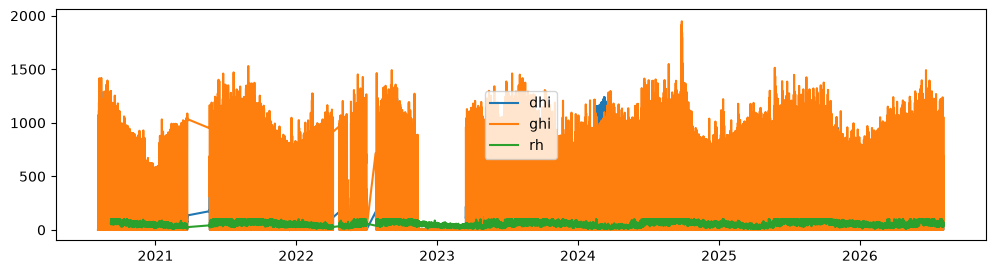

In [48]:
#| label: fig-eda-ciclo-columnas
#| fig-cap: "Las columnas cuyo nombre contiene una `h` dibujadas con un ciclo: `dhi`, `ghi` y `rh`. La humedad relativa, en porcentaje, queda aplastada junto a las irradiancias en W/m²."
#| fig-alt: "Serie naranja de irradiancia global que llega a 2000 W/m², picos azules de difusa y una línea verde casi plana al fondo que es la humedad relativa."
columnas = [columna for columna in esolmet.columns if "h" in columna]

fig, ax = plt.subplots(figsize=(12,3))

for columna in columnas:
    ax.plot(esolmet[columna],label=columna)

ax.legend(loc="center")

## `between_time` sin argumentos

La celda quedó sin ejecutar. `between_time` filtra las filas por hora del día, por ejemplo
`esolmet.between_time("06:00", "18:00")` para quedarse con las horas de sol; sin argumentos
falla.

In [ ]:
esolmet.between_time()

## Guardar un mes para la siguiente libreta

`loc` con dos fechas como texto rebana el índice del 10 de marzo al 10 de abril de 2021, y
`to_parquet` lo escribe en `data/002_intermediate/`. La celda no imprime nada: su resultado
es el archivo.

In [56]:
esolmet.loc["2021-03-10":"2021-04-10"].to_parquet("../data/002_intermediate/esolmet_1mes_3marzo.parquet")